# CMOS sensor: isolating the numerical discrepancy

## Results at a glance

**The published-reference mismatch remains.** The latest RTX3090 sensor run gives R/G/B efficiencies of **9.906/20.821/9.223%**, versus approximately **6.19/20.32/6.24%** from the digitized Tidy3D plot.

Four demonstrated issues have been corrected: accumulated float32 monitor time, incident-power calibration bias, detector H interpolation across the silicon interface, and periodic material-support assembly. The latest seam fix changes the sensor spectrum by **less than 0.001 percentage points**. It therefore does not explain this geometry's discrepancy.

Independent tiled-domain checks now agree to float32 precision for flat interfaces on uniform and graded grids. Curved supports retain quadrature error that decreases with tighter integration. Independent dispersive Fresnel checks have power errors below **0.069 percentage points** at 5 nm; a rotated static-diagonal interface converges to **0.0065 points** in reflection. These power controls do not certify transmitted phase in the coarse sensor.

The earlier metal-policy, outer-absorber and optical-depth controls also failed to close the red/blue gap. The sections below preserve their separate inputs, comparisons and limits.

This notebook executes analysis of saved GPU runs. Reproduction commands are in [the evidence report](../../docs/reviews/cmos-isolation/README.md). The [main sensor notebook](cmos_rgb_sensor.ipynb) is executed with the current dielectric and metal policies. The additional controls below compare dielectric response, metal-face ownership and lateral refinement; the independent Meep resonator result is in the [metal notebook](metal_solver_benchmarks.ipynb).

The completed full reconstructed **390×390×430** mesh gives **9.2204%** blue efficiency. Its negligible change from the 20 nm control excludes the lateral-mesh mismatch as an explanation of this blue-channel gap. Passing ADE arrays as runtime inputs made this run fit in host memory.

The broadband point-susceptibility control gives **9.545/20.108/8.497%** with the same plus-side detector. Linear colocation lowers these to **8.898/17.939/6.817%**. Neither reproduces all three published channels; production defaults are unchanged.

## Context and methods

All runs retain the imported material poles, source polarization, physical detector plane and 3 × 3 µm incident aperture. Full-sensor runs use 20 nm lateral cells, the reconstructed 430-cell reference z mesh, 510 fs and 200 frequencies. Green combines both green apertures.

### Key assumptions

- Native E-plane wave decomposition applies to a normally incident wave in uniform-grid air. It is not a general power estimator for patterned fields.
- One-sided detector sampling extrapolates H from three samples inside SiN to the original silicon interface. The stencil must remain in one smooth region.
- Planar transmission controls retain paired interpolated empty-plane normalization, so their errors include that sampling bias. The full sensor uses native incident calibration; reflection and complex-field checks provide independent evidence.
- Planar transfer matrices provide an independent physical reference. Full-sensor Tidy3D values (~6/20/6% at 650/550/450 nm) are approximate plot readings; numerical reference spectra are unavailable.
- The Tidy3D reference uses roughly 7.7 nm lateral cells and different subpixel operators. The 20 nm sensor is not a common-mesh parity test.

Sources: [published notebook](https://www.flexcompute.com/tidy3d/examples/notebooks/CMOSRGBSensor/), checked-in simulation snapshot, and the raw spectra/report JSON files loaded below.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"examples/cmos_rgb_sensor.py").exists())
evidence = root/"docs/reviews/cmos-isolation"
historical = root/"docs/reviews/cmos-polarized/reference-z-20nm-absorber"
colors = dict(red="#c43c39",green="#247b4a",blue="#3265b0")
central = dict(red=650,green=550,blue=450)
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"figure.figsize":(9,4)})
def read_report(path):
    return json.loads(path.read_text())
def combine(data, channel):
    return data["green1"]+data["green2"] if channel=="green" else data[channel]
def at_center(values, wavelength_nm, channel):
    order=np.argsort(wavelength_nm)
    return 100*np.interp(central[channel],wavelength_nm[order],values[order])
def show_table(labels, rows):
    header="| " + " | ".join(labels) + " |\n|" + "|".join(["---"]*len(labels)) + "|\n"
    display(Markdown(header + "\n".join("| " + " | ".join(map(str,r)) + " |" for r in rows)))
print("Raw inputs:", evidence.relative_to(root))

Raw inputs: docs/reviews/cmos-isolation


## Incident-power calibration

The former denominator was a colocated E × H flux on coarse air cells. The new denominator separates forward and backward waves using two native E planes and the discrete Yee wave number. Both use the complete unit-cell aperture.

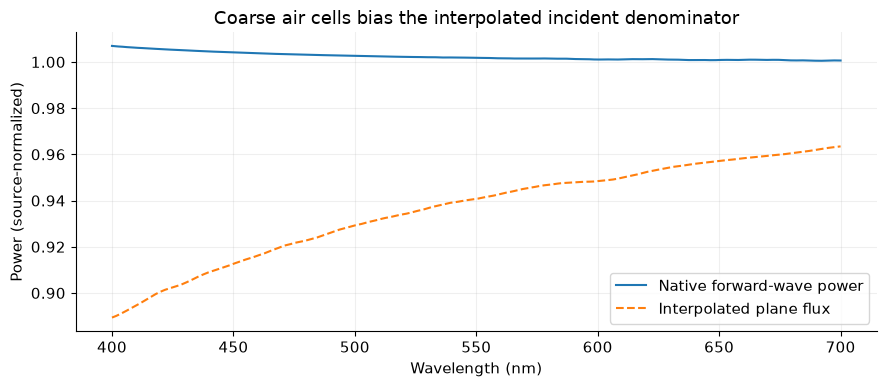

| Wavelength | Old flux / forward power |
|---|---|
| 450 nm | 0.9089 |
| 550 nm | 0.9391 |
| 650 nm | 0.9564 |

Maximum backward power: 0.0024929338759215464


In [2]:
incident=np.load(evidence/"incident/spectra.npz")
wl=incident["wavelength_nm"]
order=np.argsort(wl)
fig, ax=plt.subplots()
ax.plot(wl[order],incident["modal_power"][order],label="Native forward-wave power")
ax.plot(wl[order],incident["plane_power"][order],"--",label="Interpolated plane flux")
ax.set(xlabel="Wavelength (nm)",ylabel="Power (source-normalized)",title="Coarse air cells bias the interpolated incident denominator")
ax.grid(alpha=.2);ax.legend()
fig.tight_layout();fig.savefig(evidence/"incident_calibration.png",dpi=150);plt.show()
show_table(["Wavelength","Old flux / forward power"],[(f"{w} nm",f"{np.interp(w,wl[order],(incident['plane_power']/incident['modal_power'])[order]):.4f}") for w in (450,550,650)])
print("Maximum backward power:",float(incident["backward_power"].max()))

## Planar stack convergence and the clock defect

Each stack has a full-plane RGB filter and the same silica/SiN/silicon layers, with no lenses or metal patterns. Refinement subdivides every original z interval and preserves all original edges. Errors are maxima over 400–700 nm. The clock fix ties Fourier phase to integer timesteps rather than repeatedly adding float32 dt.

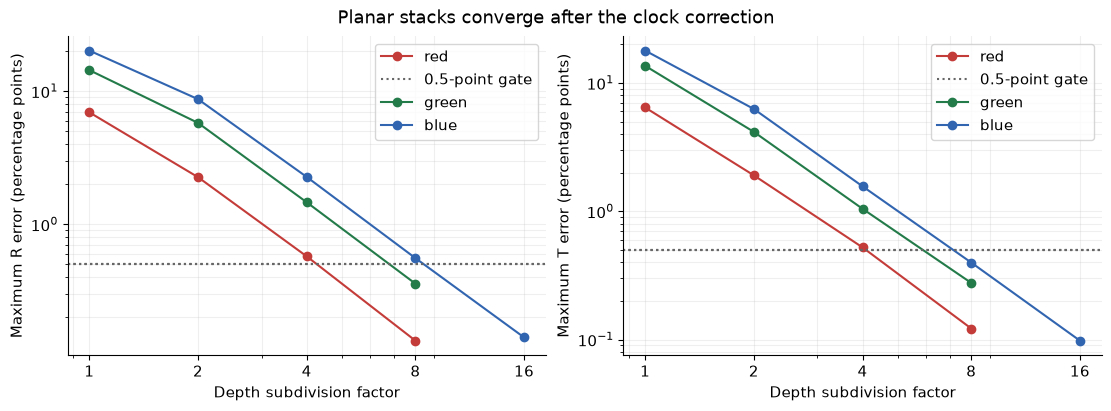

| Channel, depth ×8 | Old-clock T error (pp) | Integer-clock T error (pp) |
|---|---|---|
| red | 1.033 | 0.122 |
| green | 2.318 | 0.276 |
| blue | 3.501 | 0.398 |

| Coarse stack, central wavelength | Transmission phase error (rad) |
|---|---|
| red | 0.425 |
| green | 0.740 |
| blue | 1.350 |

In [3]:
planar=read_report(evidence/"planar/absorber/report.json")["runs"]
old_planar=read_report(evidence/"planar/absorber-accumulated-clock/report.json")["runs"]
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for channel,color in colors.items():
    rows=sorted((r for r in planar if r["channel"]==channel),key=lambda r:r["depth_refinement"])
    factors=[r["depth_refinement"] for r in rows]
    for ax,key in zip(axes,("R","T")):
        error=[r["R_error_pp"] if key=="R" else r["T_error_pp"]["one_sided"] for r in rows]
        ax.loglog(factors,error,"o-",color=color,label=channel)
        ax.set(xlabel="Depth subdivision factor",ylabel=f"Maximum {key} error (percentage points)")
        ax.axhline(.5,color="0.4",ls=":",label="0.5-point gate" if channel=="red" else None)
        ax.grid(alpha=.2,which="both")
        ax.set_xticks([1,2,4,8,16],labels=["1","2","4","8","16"])
axes[0].legend();axes[1].legend()
fig.suptitle("Planar stacks converge after the clock correction")
fig.savefig(evidence/"planar_convergence.png",dpi=150);plt.show()
rows=[]
for channel in colors:
    old=next(r for r in old_planar if r["channel"]==channel and r["depth_refinement"]==8)
    new=next(r for r in planar if r["channel"]==channel and r["depth_refinement"]==8)
    rows.append((channel,f"{old['T_error_pp']['one_sided']:.3f}",f"{new['T_error_pp']['one_sided']:.3f}"))
show_table(["Channel, depth ×8","Old-clock T error (pp)","Integer-clock T error (pp)"],rows)
phase_rows=[]
for channel in colors:
    raw=np.load(evidence/f"planar/absorber/{channel}-refine1.npz")
    phase=float(np.interp(central[channel],raw["wavelength_nm"],np.angle(raw["t"]/raw["t_exact"])))
    phase_rows.append((channel,f"{phase:.3f}"))
show_table(["Coarse stack, central wavelength","Transmission phase error (rad)"],phase_rows)

## Full sensor: separate the corrections

These comparisons retain the same geometry and detector plane. The first correction changes the DFT clock, the second changes only the incident denominator, and the third changes only H colocation. A correction need not move the result toward the published plot to be physically justified.

| Configuration | Red, 650 nm | Green, 550 nm | Blue, 450 nm |
|---|---|---|---|
| Historical | 9.785% | 20.615% | 8.849% |
| Clock corrected | 9.781% | 20.611% | 8.849% |
| + incident calibration | 9.354% | 19.354% | 8.043% |
| + one-sided detector | 9.725% | 20.652% | 9.203% |
| Published plot (approximate) | ~6% | ~20% | ~6% |

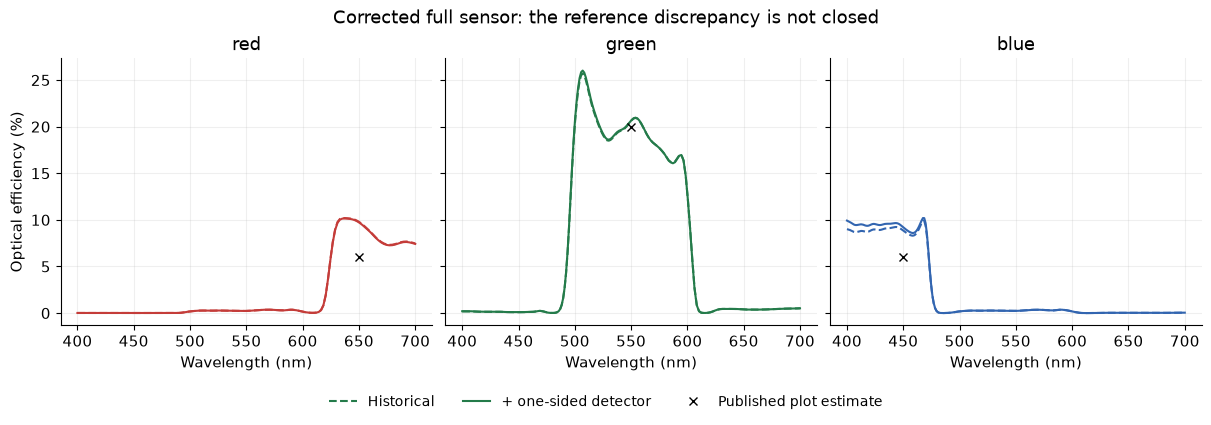

In [4]:
old_raw=np.load(historical/"sensor_spectra.npz")
old_ref=np.load(historical/"reference_spectra.npz")["incident_plane"]
linear_raw=np.load(evidence/"components/full/linear_spectra.npz")
new_raw=np.load(evidence/"components/full/sensor_spectra.npz")
current_ref=np.load(evidence/"components/full/incident_calibration.npz")
curves={"Historical":{},"Clock corrected":{},"+ incident calibration":{},"+ one-sided detector":{}}
for channel in colors:
    curves["Historical"][channel]=combine(old_raw,channel)/old_ref
    curves["Clock corrected"][channel]=combine(linear_raw,channel)/current_ref["plane_power"]
    curves["+ incident calibration"][channel]=combine(linear_raw,channel)/current_ref["modal_power"]
    curves["+ one-sided detector"][channel]=combine(new_raw,channel)/current_ref["modal_power"]
rows=[(label,*[f"{at_center(data[ch],wl,ch):.3f}%" for ch in colors]) for label,data in curves.items()]
rows.append(("Published plot (approximate)","~6%","~20%","~6%"))
show_table(["Configuration","Red, 650 nm","Green, 550 nm","Blue, 450 nm"],rows)
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
for ax,(channel,color) in zip(axes,colors.items()):
    for label,style in (("Historical","--"),("+ one-sided detector","-")):
        ax.plot(wl[order],100*curves[label][channel][order],style,color=color,label=label)
    ax.plot(central[channel],20 if channel=="green" else 6,"kx",label="Published plot estimate")
    ax.set(title=channel,xlabel="Wavelength (nm)")
    ax.grid(alpha=.2)
axes[0].set_ylabel("Optical efficiency (%)");fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=10)
fig.suptitle("Corrected full sensor: the reference discrepancy is not closed")
fig.savefig(evidence/"sensor_corrections.png",dpi=150,bbox_inches="tight");plt.show()

## Component controls

All three stages use the same mesh, source, calibration and detector reconstruction. Differences identify the effects of structures within BeamZ. They do not measure the error in Tidy3D’s handling of those structures.

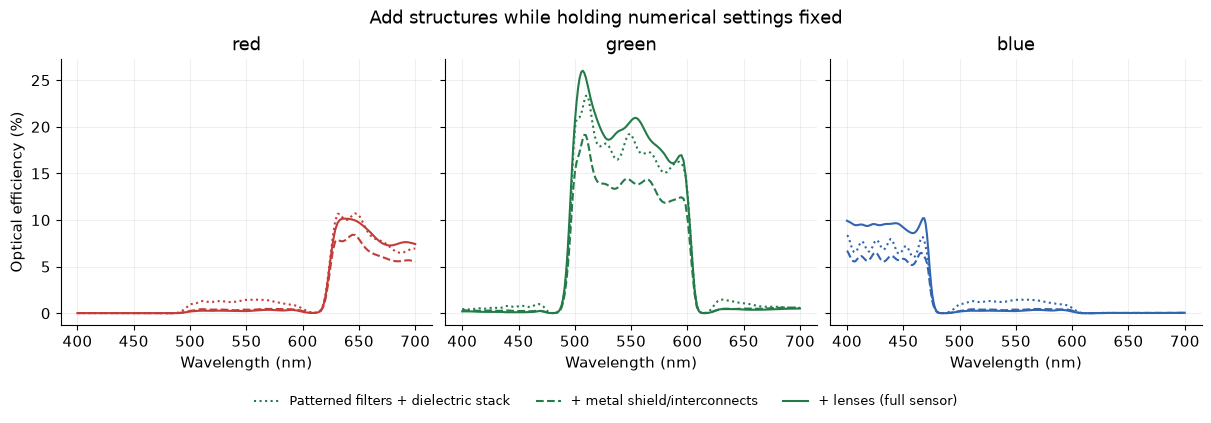

| Stage | Red | Green | Blue | Max 300–510 fs change (pp) |
|---|---|---|---|---|
| Patterned filters + dielectric stack | 10.463% | 19.123% | 6.912% | 0.0095 |
| + metal shield/interconnects | 7.949% | 14.194% | 5.831% | 0.0084 |
| + lenses (full sensor) | 9.725% | 20.652% | 9.203% | 0.0146 |

In [5]:
stages=("bare_stack","no_lenses","full")
labels={"bare_stack":"Patterned filters + dielectric stack","no_lenses":"+ metal shield/interconnects","full":"+ lenses (full sensor)"}
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
rows=[]
for stage,style in zip(stages,(":","--","-")):
    data=np.load(evidence/f"components/{stage}/calibrated_efficiency.npz")
    report=read_report(evidence/f"components/{stage}/report.json")
    rows.append((labels[stage],*[f"{report['central_efficiency_percent'][ch]:.3f}%" for ch in colors],f"{max(report['temporal_max_change_pp'].values()):.4f}"))
    for ax,(channel,color) in zip(axes,colors.items()):
        ax.plot(wl[order],100*data[channel][order],style,color=color,label=labels[stage])
        ax.set(title=channel,xlabel="Wavelength (nm)");ax.grid(alpha=.2)
axes[0].set_ylabel("Optical efficiency (%)")
fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=9)
fig.suptitle("Add structures while holding numerical settings fixed")
fig.savefig(evidence/"component_controls.png",dpi=150,bbox_inches="tight");plt.show()
show_table(["Stage","Red","Green","Blue","Max 300–510 fs change (pp)"],rows)

## Hold the timestep fixed and refine optical depth cells

This additional full-sensor control caps depth spacing at 20 nm between the silicon surface and the lens tops. It retains every original z edge, the 20 nm lateral mesh, timestep, source, detector coordinates, silicon depth cells and absorber regions. It increases z cells from 430 to 519, which fits the local RTX3090. Its own empty-cell calibration uses the same refined z mesh.

This is one controlled refinement, not proof of full spatial convergence. In particular, it does not refine the silicon depth cells or reproduce Tidy3D's lateral mesh.

The refined sensor gives **9.898/21.365/9.807%** at the central RGB wavelengths, compared with **9.725/20.652/9.203%** before refinement. All three move farther from the approximate published values. Depth resolution matters, but this change alone does not close the discrepancy.

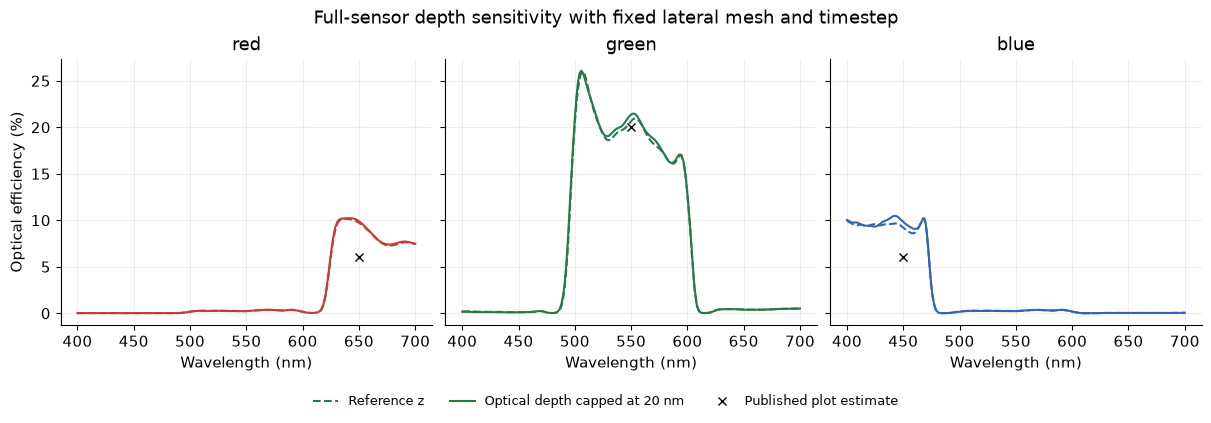

| Channel | Original z, central OE | Refined z, central OE | Max spectral change (pp) |
|---|---|---|---|
| red | 9.725% | 9.898% | 0.297 |
| green | 20.652% | 21.365% | 0.807 |
| blue | 9.203% | 9.807% | 0.815 |

Maximum late-time change in refined sensor (pp): 0.01392957745367518


In [6]:
baseline=np.load(evidence/"components/full/calibrated_efficiency.npz")
refined=np.load(evidence/"components/full-dz20nm/calibrated_efficiency.npz")
a=read_report(evidence/"components/full/report.json")
b=read_report(evidence/"components/full-dz20nm/report.json")
assert a["dt"]==b["dt"] and a["steps"]==b["steps"]
assert a["grid"][:2]==b["grid"][:2]
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
rows=[]
for ax,(channel,color) in zip(axes,colors.items()):
    ax.plot(wl[order],100*baseline[channel][order],"--",color=color,label="Reference z")
    ax.plot(wl[order],100*refined[channel][order],"-",color=color,label="Optical depth capped at 20 nm")
    ax.plot(central[channel],20 if channel=="green" else 6,"kx",label="Published plot estimate")
    ax.set(title=channel,xlabel="Wavelength (nm)");ax.grid(alpha=.2)
    rows.append((channel,f"{a['central_efficiency_percent'][channel]:.3f}%",f"{b['central_efficiency_percent'][channel]:.3f}%",f"{100*np.max(abs(refined[channel]-baseline[channel])):.3f}"))
axes[0].set_ylabel("Optical efficiency (%)");fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=9)
fig.suptitle("Full-sensor depth sensitivity with fixed lateral mesh and timestep")
fig.savefig(evidence/"sensor_depth_control.png",dpi=150,bbox_inches="tight");plt.show()
show_table(["Channel","Original z, central OE","Refined z, central OE","Max spectral change (pp)"],rows)
print("Maximum late-time change in refined sensor (pp):",max(b["temporal_max_change_pp"].values()))

## Additional exclusions and accuracy checks

A smaller timestep on the original planar z mesh separates time discretization from depth refinement. CPML versus absorber checks boundary sensitivity in the planar geometry. A 100 nm aluminum-film control checks the imported metal against transfer matrices over 400–700 nm; it does not test the complete patterned shield.

In [7]:
time_control=read_report(evidence/"planar/absorber-courant-0.35/report.json")["runs"]
boundary_control=read_report(evidence/"planar/cpml/report.json")["runs"]
depth_control=read_report(evidence/"planar/absorber-dz20nm/report.json")["runs"]
rows=[]
for channel in colors:
    base=np.load(evidence/f"planar/absorber/{channel}-refine1.npz")
    reduced_dt=np.load(evidence/f"planar/absorber-courant-0.35/{channel}-refine1.npz")
    cpml=np.load(evidence/f"planar/cpml/{channel}-refine1.npz")
    depth=next(r for r in depth_control if r["channel"]==channel)
    rows.append((channel,f"{100*np.max(abs(reduced_dt['one_sided']-base['one_sided'])):.3f}",f"{100*np.max(abs(cpml['one_sided']-base['one_sided'])):.3f}",f"{depth['T_error_pp']['one_sided']:.3f}"))
show_table(["Planar channel","Smaller-dt change (pp)","Boundary change (pp)","Capped-depth T error vs exact (pp)"],rows)
metal=read_report(evidence/"metal-film/report.json")["runs"]
show_table(["Al film spacing","Max R error (pp)","Max T error (pp)"],[(f"{r['dx_nm']:g} nm",f"{r['R_error_pp']:.4f}",f"{r['T_error_pp']:.6f}") for r in metal])
reconstruction=read_report(evidence/"reconstruction/report.json")
rows=[(f"{r['shift']:g} cell",f"{r['T_max_error_pp']['linear']:.3f}",f"{r['T_max_error_pp']['compiled_plus']:.3f}") for r in reconstruction if r["dx_nm"]==2.5]
show_table(["Silicon interface shift, 2.5 nm grid","Linear T error (pp)","One-sided T error (pp)"],rows)

| Planar channel | Smaller-dt change (pp) | Boundary change (pp) | Capped-depth T error vs exact (pp) |
|---|---|---|---|
| red | 0.342 | 0.180 | 3.713 |
| green | 0.509 | 0.040 | 7.157 |
| blue | 0.650 | 0.019 | 9.367 |

| Al film spacing | Max R error (pp) | Max T error (pp) |
|---|---|---|
| 10 nm | 2.6037 | 0.000001 |
| 5 nm | 0.9334 | 0.000000 |
| 2.5 nm | 0.2502 | 0.000000 |

| Silicon interface shift, 2.5 nm grid | Linear T error (pp) | One-sided T error (pp) |
|---|---|---|
| 0 cell | 1.750 | 0.439 |
| 0.25 cell | 1.436 | 0.408 |
| 0.5 cell | 0.327 | 0.327 |

## Takeaways

- Integer-step timing fixes a demonstrated DFT defect. The finer planar controls recover convergence rather than worsening with longer step counts.
- Native incident calibration removes a coarse-grid denominator bias. One-sided H sampling removes cross-interface interpolation while keeping the detector physically fixed.
- The coarse planar stack still has appreciable spatial error; dielectric optical thickness and the SiN/silicon boundary require depth-convergence checks, not only finer metal cells or more wavelength samples.
- At fixed timestep, the targeted optical-depth refinement changes spectra by up to 0.297/0.807/0.815 percentage points and moves central values farther from the published plot. Lateral resolution, complete depth convergence and differing interface operators still require matched tests.
- Material coefficients already match the imported snapshot. The corrected sensor still needs matched numerical Tidy3D outputs and a full-sensor spatial-convergence study before attributing or claiming closure of the remaining gap. More run time alone is not supported as the main explanation by the late-time checks above.

The raw arrays, implementation changes, limitations, and repeat commands are documented in [the evidence report](../../docs/reviews/cmos-isolation/README.md).

## Reconstruct the reference from published figures and logs

Original server arrays are not required for this approximate comparison. The published efficiency curves are digitized with a conservative ±0.15 percentage-point reading allowance; clipped portions of the green peak are omitted. The imported RGB model curves independently match the published fit images. The embedded snapshot reproduces the logged 390×390×430 grid, whereas substituting the library aluminum before remeshing does not.

The fixed-grid RTX3090 aluminum substitution below tests the material ambiguity alone. See [the reverse-engineering report](../../docs/reviews/cmos-reverse-engineering/README.md) for image calibration, source conventions and repeat commands.

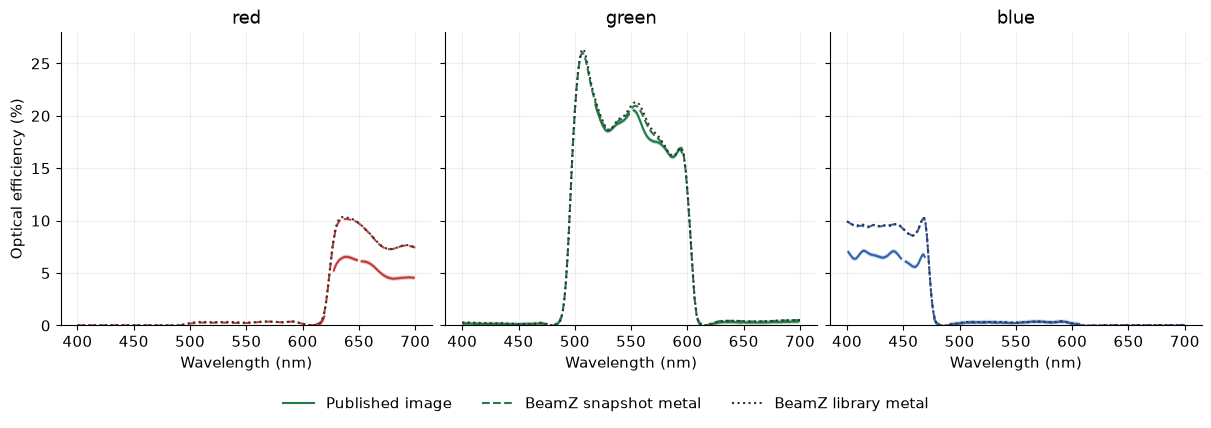

| Channel | Published image | Snapshot metal | Library metal |
|---|---|---|---|
| red | 6.19% ±0.15 pp | 9.725% | 9.755% |
| green | 20.32% ±0.15 pp | 20.652% | 20.945% |
| blue | 6.24% ±0.15 pp | 9.203% | 9.213% |

In [8]:
reverse = root / "docs/reviews/cmos-reverse-engineering"
digitized = np.load(reverse / "digitized_efficiency.npz")
aluminum = np.load(evidence / "components/full-library-metal/calibrated_efficiency.npz")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True, constrained_layout=True)
for ax, (channel, color) in zip(axes, colors.items()):
    ax.plot(digitized["wavelength_nm"], 100*digitized[channel], color=color, label="Published image")
    ax.fill_between(digitized["wavelength_nm"], 100*digitized[channel]-.15, 100*digitized[channel]+.15, color=color, alpha=.2)
    ax.plot(wl[order], 100*baseline[channel][order], "--", color=color, label="BeamZ snapshot metal")
    ax.plot(wl[order], 100*aluminum[channel][order], ":", color="0.2", label="BeamZ library metal")
    ax.set(title=channel, xlabel="Wavelength (nm)", ylim=(0,28)); ax.grid(alpha=.2)
axes[0].set_ylabel("Optical efficiency (%)")
fig.legend(*axes[1].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(.5,-.02), ncol=3, frameon=False)
fig.savefig(reverse/"aluminum_control_comparison.png", dpi=150, bbox_inches="tight"); plt.show()
published = read_report(reverse/"digitization_report.json")["channels"]
metal_report = read_report(evidence/"components/full-library-metal/report.json")
show_table(["Channel", "Published image", "Snapshot metal", "Library metal"], [(c, f"{published[c]['central_percent']:.2f}% ±0.15 pp", f"{a['central_efficiency_percent'][c]:.3f}%", f"{metal_report['central_efficiency_percent'][c]:.3f}%") for c in colors])

## What the dispersive-smoothing paper changes

Deinega and Valuev (2007), Eq. (1), constructs the full inverse tensor `β = P/H + (I−P)/A`, where `A` is the arithmetic and `H` the harmonic constituent mixture, and `P = n nᵀ`. Our present scalar law keeps the diagonal of **ε** before inversion. Keeping the diagonal of **ε⁻¹** gives a different approximation at tilted interfaces; neither retains the full coupling.

For a 50/50 silica/aluminum cell at 550 nm and a 45° normal, current effective εx is **−2.796 + 18.771i**, while inverse-diagonal truncation gives **8.679 + 1.195i**. This is a local constitutive difference, not a prediction of CMOS efficiency error. The paper's curved-metal Mie tests show why omitted off-diagonal terms need independent validation. Tidy3D defaults to metal staircasing, so the paper does not establish that Tidy3D itself uses this full-tensor method.

[Read the full paper/code/docs audit and implementation gates](../../docs/reviews/cmos-reverse-engineering/paper-interface-audit.md). Original Tidy3D arrays are no longer treated as a prerequisite for progressing these tests.

At the user's request, the default now uses staircasing for optical metals and retains diagonal Farjadpour averaging for dielectrics. The comparison below measures this policy change on the unchanged sensor grid; it does not implement the paper's full dispersive tensor.

## Metal staircasing versus diagonal averaging

Only the metal-interface policy changes here. Both runs use the snapshot aluminum, 20 nm lateral cells, the same reference depth grid, timestep, source and 510 fs duration. Dielectric interfaces retain diagonal averaging. Metal identity uses Re(εr) < 1 at the source center frequency; the exact source and input checksums are recorded with each run.

The new default uses geometric point ownership at every electric Yee location for both ε∞ and the complete causal polarization. The previous policy remains available as `RasterOptions(metal_smoothing="inherit")`. These curves compare the two implementations with the digitized published plot; the shaded ±0.15 percentage-point allowance represents image-reading uncertainty, not a statistical confidence interval.

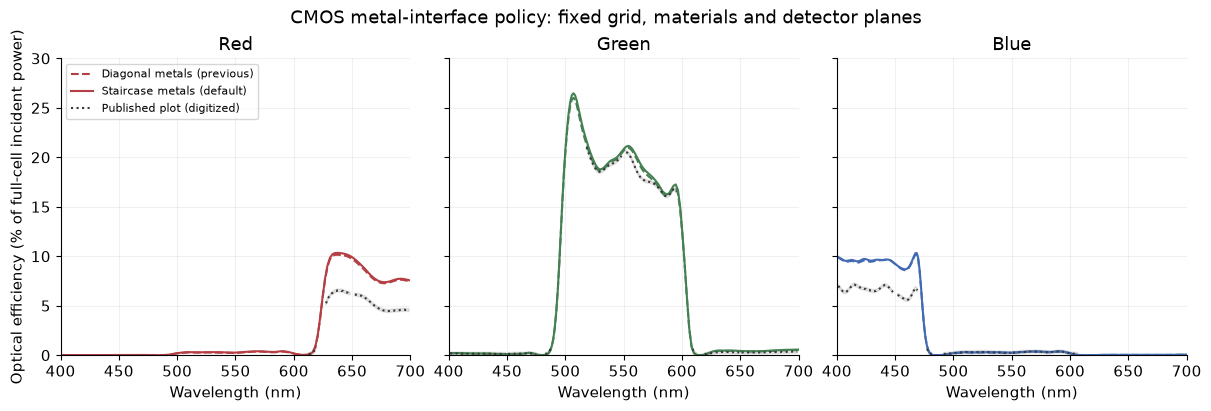

| Channel | Diagonal metals | Staircase metals | Change (pp) | Published plot |
|---|---:|---:|---:|---:|
| Red (650 nm) | 9.725% | 9.906% | +0.181 | ~6.19% |
| Green (550 nm) | 20.652% | 20.821% | +0.169 | ~20.32% |
| Blue (450 nm) | 9.203% | 9.223% | +0.020 | ~6.24% |


Maximum 300–510 fs change: Red: 0.0018 pp, Green: 0.0152 pp, Blue: 0.0017 pp


In [9]:
staircase_dir = evidence / "components/full-staircase-metal"
staircase = np.load(staircase_dir / "calibrated_efficiency.npz")
diagonal = np.load(evidence / "components/full/calibrated_efficiency.npz")
stair_report = read_report(staircase_dir / "report.json")
diag_report = read_report(evidence / "components/full/report.json")
for key in ("grid", "dt", "steps", "snapshot_sha256", "colocation_side"):
    assert stair_report[key] == diag_report[key], (key, stair_report[key], diag_report[key])
# Calibration files were recomputed from identical native fields. Compare
# their numerical content, not container checksums or last-bit arithmetic.
old_incident = np.load(evidence / "components/full/incident_calibration.npz")
new_incident = np.load(staircase_dir / "incident_calibration.npz")
for key in ("E0", "E1", "planes", "wavelength_nm", "plane_power"):
    np.testing.assert_array_equal(old_incident[key], new_incident[key])
np.testing.assert_allclose(old_incident["modal_power"], new_incident["modal_power"], rtol=5e-14, atol=0)
assert stair_report["metal_smoothing"] == "staircase"
np.testing.assert_array_equal(staircase["wavelength_nm"], diagonal["wavelength_nm"])
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)
comparison = {}
table = "| Channel | Diagonal metals | Staircase metals | Change (pp) | Published plot |\n|---|---:|---:|---:|---:|\n"
for ax, (channel, center), color in zip(axes, (("red",650),("green",550),("blue",450)), ("#b43e43", "#458052", "#426ab3")):
    wl = staircase["wavelength_nm"]
    order = np.argsort(wl)
    ax.plot(wl[order], 100*diagonal[channel][order], "--", color=color, label="Diagonal metals (previous)")
    ax.plot(wl[order], 100*staircase[channel][order], color=color, label="Staircase metals (default)")
    ref_wl = digitized["wavelength_nm"]
    ref = 100*digitized[channel]
    valid = np.isfinite(ref)
    ax.plot(ref_wl, ref, ":", color="#383838", label="Published plot (digitized)")
    ax.fill_between(ref_wl, ref-0.15, ref+0.15, color="#383838", alpha=0.12)
    old_value = float(100*np.interp(center, wl[order], diagonal[channel][order]))
    new_value = float(100*np.interp(center, wl[order], staircase[channel][order]))
    reference_value = float(np.interp(center, ref_wl[valid], ref[valid]))
    comparison[channel] = dict(diagonal_percent=old_value, staircase_percent=new_value,
        published_plot_percent=reference_value, central_change_pp=new_value-old_value,
        max_spectral_change_pp=float(100*np.max(abs(staircase[channel]-diagonal[channel]))))
    table += f"| {channel.title()} ({center} nm) | {old_value:.3f}% | {new_value:.3f}% | {new_value-old_value:+.3f} | ~{reference_value:.2f}% |\n"
    ax.set(title=channel.title(), xlabel="Wavelength (nm)", xlim=(400,700), ylim=(0,30))
    ax.grid(alpha=0.18)
axes[0].set_ylabel("Optical efficiency (% of full-cell incident power)")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("CMOS metal-interface policy: fixed grid, materials and detector planes")
fig.savefig(staircase_dir / "metal_policy_comparison.png", dpi=160)
plt.show()
display(Markdown(table))
(staircase_dir / "metal_policy_comparison.json").write_text(json.dumps(comparison, indent=2)+"\n")
print("Maximum 300–510 fs change:", ", ".join(f"{c.title()}: {v:.4f} pp" for c, v in stair_report["temporal_max_change_pp"].items()))


The metal-policy change is small compared with the remaining red/blue gap. It therefore rules out the previous metal smoothing choice as a sufficient explanation **on this grid**. It does not prove convergence of either method. The next accuracy checks remain spatial refinement with a fixed policy and independent curved-interface benchmarks; changing to the paper's full tensor would be a separate implementation.

The calibration NPZ checksums differ because the derived wave number and modal power were recomputed with last-bit floating-point differences. The native calibration fields and plane coordinates are bit-identical, and the incident powers agree to within `5e-14` relative tolerance. That cannot account for the measured efficiency changes.

## Full-sensor outer-boundary control

The public Tidy3D notebook uses periodic x/y and adiabatic absorbers in z. This control replaces only BeamZ's z absorbers with CPML, retaining metal staircasing, materials, physical geometry, mesh, source, detector reconstruction, timestep and 510 fs duration. Each boundary configuration uses its own empty-cell native-wave calibration. Periodic x/y boundaries and internal material-interface averaging are unchanged; this is not a test of those operators.


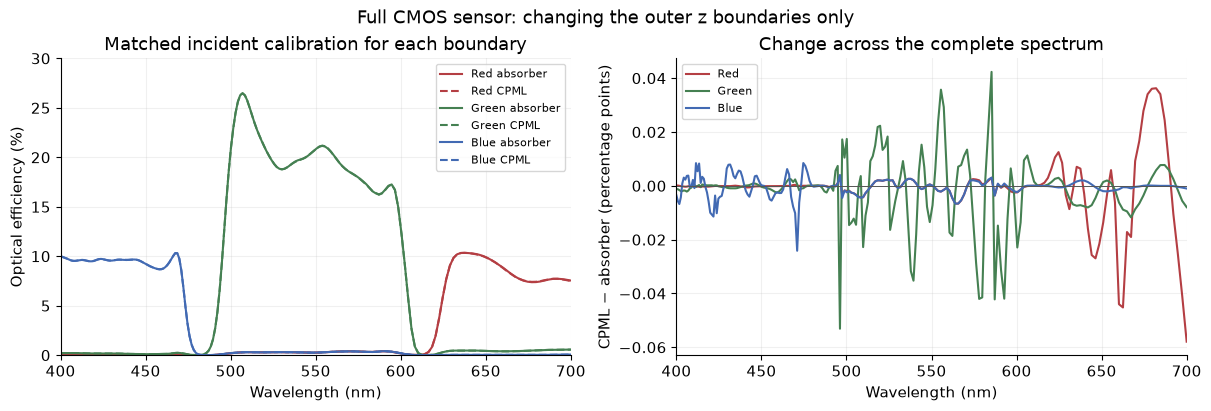

| Channel | Absorber | CPML | Change (pp) | Max spectral change (pp) |
|---|---:|---:|---:|---:|
| Red (650 nm) | 9.906% | 9.889% | -0.017 | 0.058 |
| Green (550 nm) | 20.821% | 20.812% | -0.009 | 0.053 |
| Blue (450 nm) | 9.223% | 9.224% | +0.000 | 0.024 |


Maximum 300–510 fs change: Red: 0.0054 pp, Green: 0.0353 pp, Blue: 0.0026 pp


In [10]:
cpml_dir = evidence / "components/full-staircase-metal-cpml"
cpml = np.load(cpml_dir / "calibrated_efficiency.npz")
cpml_report = read_report(cpml_dir / "report.json")
for key in ("grid", "dt", "steps", "snapshot_sha256", "colocation_side", "metal_smoothing", "reference_frequency_hz"):
    assert cpml_report[key] == stair_report[key], key
for axis in "xyz":
    np.testing.assert_array_equal(np.load(cpml_dir / "grid.npz")[axis], np.load(staircase_dir / "grid.npz")[axis])
np.testing.assert_array_equal(cpml["wavelength_nm"], staircase["wavelength_nm"])
assert cpml_report["boundary"] == "cpml"
assert read_report(cpml_dir / "incident_calibration_report.json")["boundary"] == "cpml"
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
comparison = {}
table = "| Channel | Absorber | CPML | Change (pp) | Max spectral change (pp) |\n|---|---:|---:|---:|---:|\n"
wl = cpml["wavelength_nm"]
order = np.argsort(wl)
for channel, center, color in (("red",650,"#b43e43"),("green",550,"#458052"),("blue",450,"#426ab3")):
    delta = 100*(cpml[channel]-staircase[channel])
    old_value = stair_report["central_efficiency_percent"][channel]
    new_value = cpml_report["central_efficiency_percent"][channel]
    comparison[channel] = dict(absorber_percent=old_value, cpml_percent=new_value,
        central_change_pp=new_value-old_value, max_spectral_change_pp=float(np.max(abs(delta))),
        temporal_max_change_pp=cpml_report["temporal_max_change_pp"][channel])
    axes[0].plot(wl[order], 100*staircase[channel][order], color=color, label=channel.title()+" absorber")
    axes[0].plot(wl[order], 100*cpml[channel][order], "--", color=color, label=channel.title()+" CPML")
    axes[1].plot(wl[order], delta[order], color=color, label=channel.title())
    table += f"| {channel.title()} ({center} nm) | {old_value:.3f}% | {new_value:.3f}% | {new_value-old_value:+.3f} | {np.max(abs(delta)):.3f} |\n"
axes[0].set(ylabel="Optical efficiency (%)", ylim=(0,30), title="Matched incident calibration for each boundary")
axes[1].axhline(0, color="#555555", linewidth=0.7)
axes[1].set(ylabel="CPML − absorber (percentage points)", title="Change across the complete spectrum")
for ax in axes:
    ax.set(xlabel="Wavelength (nm)", xlim=(400,700))
    ax.grid(alpha=0.18)
    ax.legend(fontsize=8)
fig.suptitle("Full CMOS sensor: changing the outer z boundaries only")
fig.savefig(cpml_dir / "boundary_comparison.png", dpi=160)
plt.show()
display(Markdown(table))
(cpml_dir / "boundary_comparison.json").write_text(json.dumps(comparison, indent=2)+"\n")
print("Maximum 300–510 fs change:", ", ".join(f"{c.title()}: {v:.4f} pp" for c, v in cpml_report["temporal_max_change_pp"].items()))


Changing only the outer z absorption changes central R/G/B by **−0.017/−0.009/+0.0003 percentage points**; maximum changes across the full spectra are **0.058/0.053/0.024 points**. These are much smaller than the remaining ~3.72/~2.98-point red/blue gaps. The full-sensor control therefore does not support the outer z absorbers as the dominant cause on this grid. All saved arrays are finite; the largest 300–510 fs change is 0.0354 points, so the smallest boundary differences should not be interpreted as precision measurements.

This leaves the discrepancy unresolved. Periodic seams, internal dielectric-interface operators, full spatial convergence and fidelity to the published reference remain separate attribution questions. Demonstrated planar discretization errors do not by themselves identify which of these explains the sensor mismatch.

## Independent periodic-material checks

A periodic 16×16×4 cell is compared with the central tile of an independently rasterized 3×3 array. The initial fields repeat exactly; eight timesteps cannot bring errors from the reference domain's outer seams into its central tile. Tilted stripes integrate exactly, so this test separates seam assembly from quadrature accuracy.

**Two defects were found:** static voxel coefficients retained clipped half supports, and dispersive diagonal interfaces averaged already-smoothed halves. Harmonic averaging is nonlinear: the fractions of the full wrapped support must be assembled first. The native fix now shares those fractions across static coefficients and ADE indicators/interfaces, retains one metal point owner and uses complete-support curvature gates. Boundary topology participates in raster caches.

Flat tests use both uniform and graded cells, static and Lorentz dielectrics, and volume and diagonal averaging. Curved cylinder supports also test the remaining adaptive integration error. The initial historical curved probe used a different transverse cell count, so only the matched flat probe is used for the before/after chart.

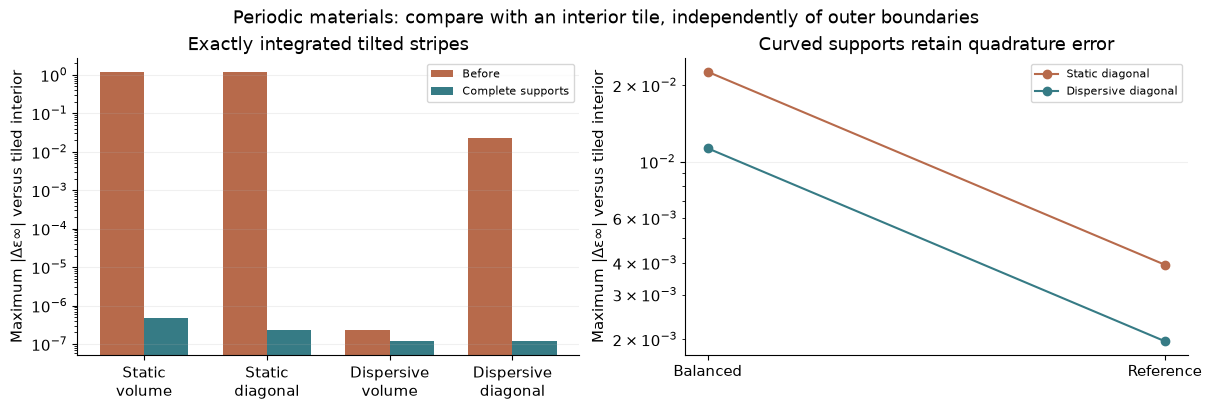

Largest corrected flat/graded coefficient difference: 4.76837158203125e-07
Largest reference-quality curved coefficient difference: 0.003933429718017578


In [11]:
seam_dir = evidence / "periodic-interfaces"
flat_before = read_report(seam_dir / "flat-before.json")
flat_after = read_report(seam_dir / "flat-after.json")["runs"]
graded_after = read_report(seam_dir / "graded-after.json")["runs"]
curved_after = read_report(seam_dir / "curved-after.json")["runs"]
curved_reference = read_report(seam_dir / "curved-reference-after.json")["runs"]
for row in flat_after + graded_after:
    assert max(row["epsilon_max_difference"].values()) < 1e-6
    assert max(v for errors in row["field_max_difference"].values() for v in errors.values()) < 1e-6
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
labels = ["Static\nvolume", "Static\ndiagonal", "Dispersive\nvolume", "Dispersive\ndiagonal"]
x = np.arange(4)
axes[0].bar(x-.18, [max(r["epsilon_max_difference"].values()) for r in flat_before], .36, label="Before", color="#b76a4b")
axes[0].bar(x+.18, [max(r["epsilon_max_difference"].values()) for r in flat_after], .36, label="Complete supports", color="#367b85")
axes[0].set(xticks=x, xticklabels=labels, yscale="log", ylabel="Maximum |Δε∞| versus tiled interior", title="Exactly integrated tilted stripes")
axes[0].legend(fontsize=8)
for dispersive, label, color in ((False,"Static diagonal","#b76a4b"),(True,"Dispersive diagonal","#367b85")):
    values = [max(next(r for r in rows if r["dispersive"] == dispersive and r["smoothing"] == "farjadpour_diagonal")["epsilon_max_difference"].values()) for rows in (curved_after, curved_reference)]
    assert values[1] < values[0]
    axes[1].plot([0,1], values, "o-", label=label, color=color)
axes[1].set(xticks=[0,1], xticklabels=["Balanced", "Reference"], yscale="log", ylabel="Maximum |Δε∞| versus tiled interior", title="Curved supports retain quadrature error")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="y", alpha=.18)
fig.suptitle("Periodic materials: compare with an interior tile, independently of outer boundaries")
fig.savefig(seam_dir / "seam_comparison.png", dpi=160)
plt.show()
print("Largest corrected flat/graded coefficient difference:", max(max(r["epsilon_max_difference"].values()) for r in flat_after+graded_after))
print("Largest reference-quality curved coefficient difference:", max(max(r["epsilon_max_difference"].values()) for r in curved_reference))


## Independent dielectric-interface physics checks

The imported silica and silicon-nitride pole models are checked against **complex Fresnel admittances** at 450 and 650 nm, 30° incidence, TE/TM polarization, a quarter-cell interface shift, and 10/5 nm grids. Each measured frequency has exactly one transverse wavelength in the periodic cell. Transmission is sampled four cells into homogeneous material and the analytical value includes that propagation loss. Each device uses a matching empty-domain reference; reported errors include field sampling and source discretization.

A separate **source-free, lossless TE pulse** hits an n=1.5 half-space normally, with the interface rotated by 0° or 45° relative to the grid. Fresnel reflectance is exactly 4% at every pulse frequency. A central strip is measured before radiation from distant boundaries can reach it; E/H are colocated in space and time, and a matching empty-domain pulse provides the denominator. This tests the diagonal approximation away from grid-aligned surfaces without using periodic seams. It does not certify arbitrary curved, high-contrast, off-diagonal dispersive response.

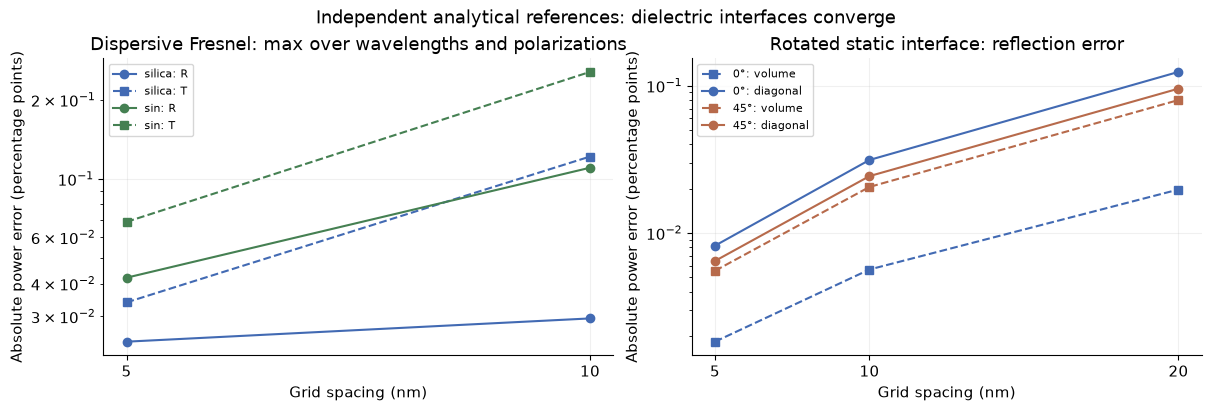

At 5 nm: maximum dispersive R/T errors (pp): 0.04210116288900778 0.06867137748759466
At 5 nm, rotated 45° diagonal reflection error (pp): -0.006451298217800827


In [12]:
fresnel = read_report(seam_dir / "fresnel.json")["runs"]
rotated = read_report(seam_dir / "rotated-fresnel.json")["runs"]
assert len(fresnel) == 16 and len(rotated) == 12
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for material, color in (("silica", "#426ab3"), ("sin", "#458052")):
    for metric, style in (("R", "o-"), ("T", "s--")):
        values = [max(abs(r[metric+"_error_pp"]) for r in fresnel if r["material"] == material and r["dx_nm"] == dx) for dx in (5,10)]
        axes[0].plot([5,10], values, style, color=color, label=f"{material}: {metric}")
axes[0].set(title="Dispersive Fresnel: max over wavelengths and polarizations", xticks=[5,10])
for angle, color in ((0,"#426ab3"),(45,"#b76a4b")):
    for smoothing, style, label in (("volume","s--","volume"),("farjadpour_diagonal","o-","diagonal")):
        values = [abs(next(r for r in rotated if r["interface_angle_degrees"] == angle and r["smoothing"] == smoothing and r["dx_nm"] == dx)["R_error_pp"]) for dx in (5,10,20)]
        assert values[0] < values[1] < values[2]
        axes[1].plot([5,10,20], values, style, color=color, label=f"{angle}°: {label}")
axes[1].set(title="Rotated static interface: reflection error", xticks=[5,10,20])
for ax in axes:
    ax.set(xlabel="Grid spacing (nm)", ylabel="Absolute power error (percentage points)", yscale="log")
    ax.grid(alpha=.18)
    ax.legend(fontsize=8)
fig.suptitle("Independent analytical references: dielectric interfaces converge")
fig.savefig(seam_dir / "dielectric_fresnel_comparison.png", dpi=160)
plt.show()
fine = [r for r in fresnel if r["dx_nm"] == 5]
assert max(abs(r["T_error_pp"]) for r in fine) < .069
assert max(abs(r["R_error_pp"]) for r in fine) < .043
print("At 5 nm: maximum dispersive R/T errors (pp):", *(max(abs(r[m+"_error_pp"]) for r in fine) for m in ("R","T")))
print("At 5 nm, rotated 45° diagonal reflection error (pp):", next(r["R_error_pp"] for r in rotated if r["dx_nm"] == 5 and r["interface_angle_degrees"] == 45 and r["smoothing"] == "farjadpour_diagonal"))


## Full CMOS sensor after the seam fix

This RTX3090 run retains the 150×150×430 mesh, 510 fs duration, snapshot materials, metal staircasing, dielectric diagonal averaging, outer absorbers, source and detectors. Only periodic material-support assembly changes. The existing homogeneous-air calibration is unchanged by that assembly and is reused exactly. The numerical implementation is commit `bdc02402`; the later boundary-iterator input fix does not change these list-specified boundaries.


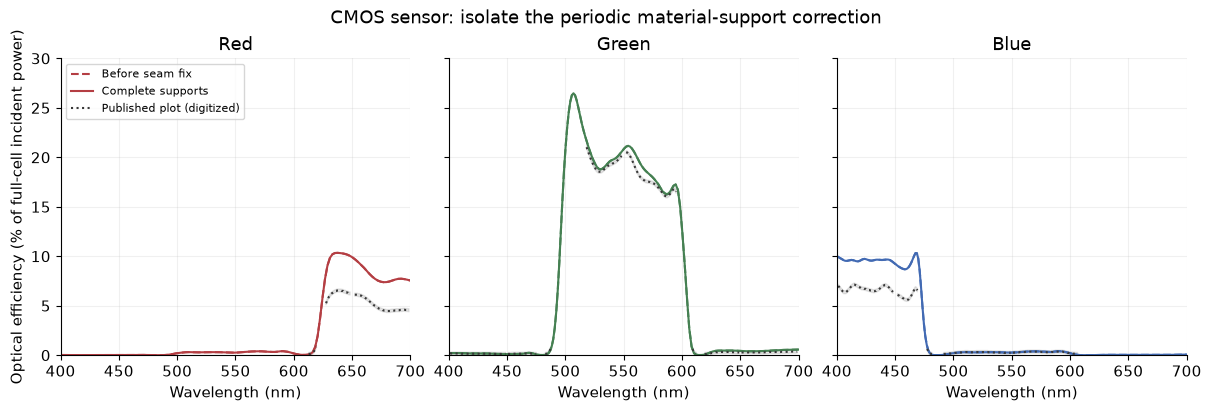

| Channel | Before seam fix | Complete supports | Change (pp) | Published plot |
|---|---:|---:|---:|---:|
| Red (650 nm) | 9.906% | 9.906% | -0.000072 | ~6.19% |
| Green (550 nm) | 20.821% | 20.821% | +0.000042 | ~20.32% |
| Blue (450 nm) | 9.223% | 9.223% | -0.000050 | ~6.24% |


Maximum 300–510 fs change: Red: 0.0018 pp, Green: 0.0153 pp, Blue: 0.0017 pp


In [13]:
periodic_dir = evidence / "components/full-periodic-supports"
periodic = np.load(periodic_dir / "calibrated_efficiency.npz")
periodic_report = read_report(periodic_dir / "report.json")
for key in ("grid", "dt", "steps", "snapshot_sha256", "colocation_side", "metal_smoothing", "reference_frequency_hz", "modal_reference_sha256"):
    assert periodic_report[key] == stair_report[key], key
assert periodic_report["boundary"] == "absorber"
for axis in "xyz":
    np.testing.assert_array_equal(np.load(periodic_dir / "grid.npz")[axis], np.load(staircase_dir / "grid.npz")[axis])
np.testing.assert_array_equal(periodic["wavelength_nm"], staircase["wavelength_nm"])
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)
comparison = {}
table = "| Channel | Before seam fix | Complete supports | Change (pp) | Published plot |\n|---|---:|---:|---:|---:|\n"
for ax, (channel, center), color in zip(axes, (("red",650),("green",550),("blue",450)), ("#b43e43", "#458052", "#426ab3")):
    wl = periodic["wavelength_nm"]
    order = np.argsort(wl)
    ax.plot(wl[order], 100*staircase[channel][order], "--", color=color, label="Before seam fix")
    ax.plot(wl[order], 100*periodic[channel][order], color=color, label="Complete supports")
    ref_wl = digitized["wavelength_nm"]
    ref = 100*digitized[channel]
    valid = np.isfinite(ref)
    ax.plot(ref_wl, ref, ":", color="#383838", label="Published plot (digitized)")
    ax.fill_between(ref_wl, ref-.15, ref+.15, color="#383838", alpha=.12)
    old_value = stair_report["central_efficiency_percent"][channel]
    new_value = periodic_report["central_efficiency_percent"][channel]
    reference_value = float(np.interp(center, ref_wl[valid], ref[valid]))
    comparison[channel] = dict(before_percent=old_value, after_percent=new_value, published_plot_percent=reference_value,
        central_change_pp=new_value-old_value, remaining_gap_pp=new_value-reference_value,
        max_spectral_change_pp=float(100*np.max(abs(periodic[channel]-staircase[channel]))))
    table += f"| {channel.title()} ({center} nm) | {old_value:.3f}% | {new_value:.3f}% | {new_value-old_value:+.6f} | ~{reference_value:.2f}% |\n"
    ax.set(title=channel.title(), xlabel="Wavelength (nm)", xlim=(400,700), ylim=(0,30))
    ax.grid(alpha=.18)
axes[0].set_ylabel("Optical efficiency (% of full-cell incident power)")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("CMOS sensor: isolate the periodic material-support correction")
fig.savefig(periodic_dir / "seam_sensor_comparison.png", dpi=160)
plt.show()
display(Markdown(table))
(periodic_dir / "seam_sensor_comparison.json").write_text(json.dumps(comparison, indent=2)+"\n")
print("Maximum 300–510 fs change:", ", ".join(f"{c.title()}: {v:.4f} pp" for c, v in periodic_report["temporal_max_change_pp"].items()))


The seam correction changes central R/G/B by **−0.000072/+0.000042/−0.000050 percentage points**. Maximum changes over all 200 frequencies are **0.000630/0.000990/0.000326 points**, much smaller than the remaining **3.719/0.503/2.979-point** differences from the digitized plot. Late-time changes are up to 0.0153 points, so these tiny differences are not a claim of physical accuracy to six decimal places.

The periodic-material defect is fixed, but it does not explain this CMOS discrepancy on the tested grid. The independent dielectric power controls converge. They do not certify transmitted phase or arbitrary curved/high-contrast dispersive interfaces; full spatial convergence and the remaining reference mismatch are still open.

## Follow-up: constitutive response and interface conventions

These controls hold the imported geometry, physical detector planes, source and reference depth mesh fixed. Volume averaging changes only dielectric interface treatment. The frozen-dielectric diagnostic reproduces the original diagonal complex response **at 450 nm**, retaining the original aluminum poles; it is not a replacement broadband model. Closed metal faces change point ownership only where a Yee site lies on a metal box face.

All full-CMOS measurements use the RTX3090. The [follow-up report](../../docs/reviews/cmos-parity-followup/README.md) includes commands, the slab-raster equivalence test and independent Meep assumptions.

In [14]:
followup = root / "docs/reviews/cmos-parity-followup"
followup_summary = read_report(followup / "summary.json")
volume = read_report(followup / "full-volume/report.json")["central_efficiency_percent"]
frozen = read_report(followup / "frozen-450nm-dx20nm/report.json")
closed = read_report(followup / "frozen-450nm-dx20nm-closed-metal-faces/report.json")
baseline = read_report(evidence / "components/full-periodic-supports/report.json")["central_efficiency_percent"]
table = "| 510 fs, 20 nm lateral | Red (%) | Green sum (%) | Blue (%) |\n|---|---:|---:|---:|\n"
for label, values in (("Diagonal dielectric averaging", baseline), ("Volume dielectric averaging", volume)):
    table += f"| {label} | {values['red']:.5f} | {values['green']:.5f} | {values['blue']:.5f} |\n"
display(Markdown(table))
print("Frozen dielectric vs broadband blue:", round(followup_summary["frozen_minus_broadband_blue_pp"], 6), "percentage points")
print("Closed metal faces vs native blue:", round(followup_summary["closed_faces_minus_native_blue_pp"], 6), "percentage points")

| 510 fs, 20 nm lateral | Red (%) | Green sum (%) | Blue (%) |
|---|---:|---:|---:|
| Diagonal dielectric averaging | 9.90563 | 20.82106 | 9.22332 |
| Volume dielectric averaging | 9.90872 | 20.81053 | 9.22356 |


Frozen dielectric vs broadband blue: -0.000802 percentage points
Closed metal faces vs native blue: 0.061816 percentage points


Volume averaging changes central efficiencies by at most **0.011 percentage points**; the single-frequency dielectric representation changes blue by **−0.000802 points**. Closing metal box faces changes blue by **+0.061816 points**, away from the published result. None explains the several-point red/blue discrepancy.

In the separate uniform-grid common-Drude resonator, matching Meep's coefficient ownership reduces the 850 nm reflection difference from 4.312 to 0.012 points. The residual across the full 41-frequency band reaches 0.412 points. This is a useful independent solver check, but it does not establish that Tidy3D uses the same ownership or explain CMOS.

## Follow-up: finer lateral grid at fixed depth mesh

The 10 nm run uses 300×300×430 cells, the original timestep and the verified frozen-dielectric response at 450 nm. Its 300 fs checkpoint is compared with a separate uninterrupted 510 fs run. Reported checkpoint-to-final differences therefore include reproducibility across two runs.

The complete reconstructed reference grid is 390×390×430. Earlier large JAX compilations and allocator/cache-only attempts reached the host-memory guard. Passing the full-grid ADE coefficients as runtime inputs instead of captured constants removes that compilation bottleneck. The completed 510 fs run gives **9.220386%** blue efficiency, only **−0.002135 percentage points** from the equivalent 20 nm control; peak host RSS is 9.34 GiB. The saved summary explicitly distinguishes a completed numerical result from an attempted setup. A 10 nm result is not an exact common-mesh comparison.

| Blue-efficiency control | Efficiency (%) |
|---|---:|
| 20 nm, broadband ADE, 510 fs | 9.223323 |
| 20 nm, frozen dielectric, 510 fs | 9.222521 |
| 20 nm, closed metal faces, 510 fs | 9.284337 |
| 10 nm, frozen dielectric, 300 fs | 9.204278 |
| 10 nm, frozen dielectric, 510 fs | 9.204162 |
| Reconstructed reference xy, 510 fs | 9.220386 |
| 20 nm, point dielectric response, 510 fs | 8.501165 |
| Published plot (±0.15 percentage points) | ≈6.244360 |

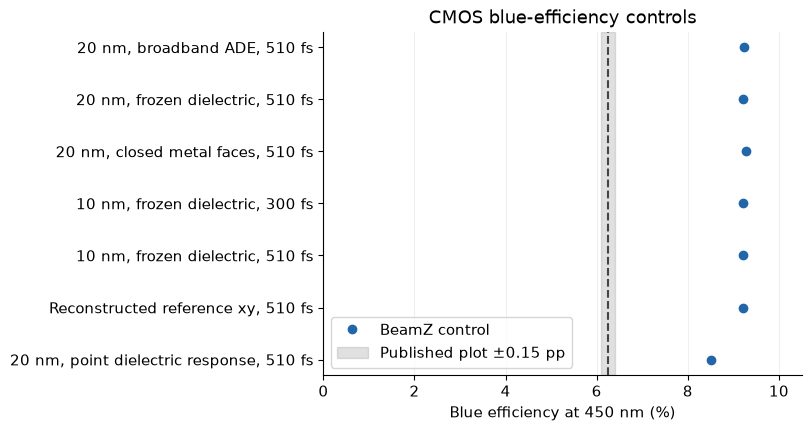

Full reconstructed grid completed: True
10 nm minus 20 nm: -0.018359851868273935 percentage points
10 nm checkpoint-to-final: -0.00011676556668405169 percentage points


In [15]:
fine = followup_summary["lateral_10nm"]
rows = [("20 nm, broadband ADE, 510 fs", baseline["blue"]),
        ("20 nm, frozen dielectric, 510 fs", frozen["efficiency_percent"]["blue"]),
        ("20 nm, closed metal faces, 510 fs", closed["efficiency_percent"]["blue"]),
        ("10 nm, frozen dielectric, 300 fs", fine["checkpoint_blue_percent"])]
if fine["completed_510fs"]:
    rows.append(("10 nm, frozen dielectric, 510 fs", fine["blue_percent"]))
if followup_summary["exact_mesh_completed"]:
    rows.append(("Reconstructed reference xy, 510 fs", followup_summary["exact_mesh_blue_percent"]))
if "point_susceptibility" in followup_summary:
    rows.append(("20 nm, point dielectric response, 510 fs", followup_summary["point_susceptibility"]["blue_percent"]))
table = "| Blue-efficiency control | Efficiency (%) |\n|---|---:|\n"
for label, value in rows:
    table += f"| {label} | {value:.6f} |\n"
table += "| Published plot (±0.15 percentage points) | ≈6.244360 |"
display(Markdown(table))
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
y = np.arange(len(rows))
ax.plot([v for _, v in rows], y, "o", color="#2266aa", label="BeamZ control")
ax.axvspan(6.244359842075579-.15, 6.244359842075579+.15,
           color="#999999", alpha=.3, label="Published plot ±0.15 pp")
ax.axvline(6.244359842075579, color="#444444", linestyle="--")
ax.set(yticks=y, yticklabels=[label for label, _ in rows], xlabel="Blue efficiency at 450 nm (%)",
       title="CMOS blue-efficiency controls", xlim=(0, 10.5))
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
ax.legend(loc="lower left")
fig.savefig(followup / "blue_controls.png", dpi=160)
plt.show()
print("Full reconstructed grid completed:", followup_summary["exact_mesh_completed"])
if fine["completed_510fs"]:
    print("10 nm minus 20 nm:", fine["fine_minus_coarse_blue_pp"], "percentage points")
    print("10 nm checkpoint-to-final:", fine["checkpoint_to_final_blue_change_pp"], "percentage points")

The point-susceptibility control keeps BeamZ's diagonal ε∞ coefficients and metal ownership fixed but point-samples the dielectric dispersive contribution. [Meep documents](https://meep.readthedocs.io/en/stable/Subpixel_Smoothing/) averaging only the instantaneous response. This tests that distinction; it does **not** reproduce Meep's full tensor and tie conventions, or establish Tidy3D's private implementation. Metal-owner equality and passive dielectric coefficients are checked before the run.

## Follow-up: broadband point susceptibility and detector reconstruction

One additional RTX3090 broadband run records all 200 frequencies and both detector reconstructions. Only the dielectric dispersive supports change; metal ownership, smoothed instantaneous permittivity, mesh, time step, source and native incident calibration stay fixed. The upper row uses H extrapolated from the plus side at the same physical detector plane; the lower row uses linear colocation. The gray band is the published-image reading allowance of ±0.15 percentage points, not a solver uncertainty interval. This comparison tests sensitivity to both choices without moving the detector or fitting the material models.

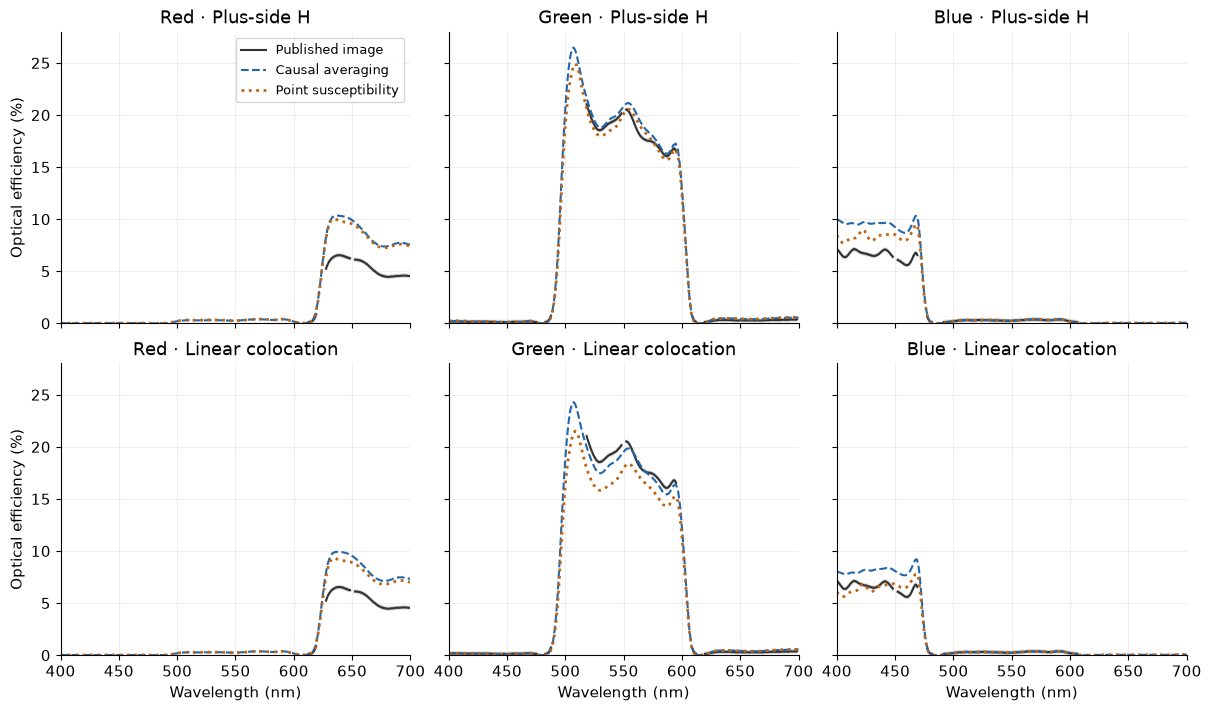

| Channel | Published (%) | Causal / plus (%) | Point / plus (%) | Causal / linear (%) | Point / linear (%) |
|---|---|---|---|---|---|
| red | 6.187 | 9.906 | 9.545 | 9.528 | 8.898 |
| green | 20.318 | 20.821 | 20.108 | 19.513 | 17.939 |
| blue | 6.244 | 9.223 | 8.497 | 8.060 | 6.817 |

Maximum 300-to-510 fs change over each spectrum (percentage points): {'red': 0.001607, 'green': 0.016114, 'blue': 0.001629}
450 nm frozen minus broadband point-susceptibility result (percentage points): 0.0037383185654498163


In [16]:
point_dir = followup / "full-point-dielectric"
point_report = read_report(point_dir / "report.json")
base_dir = evidence / "components/full-periodic-supports"
base_report = read_report(base_dir / "report.json")
for key in ("grid", "dt", "steps", "modal_reference_sha256", "snapshot_sha256"):
    assert point_report[key] == base_report[key], key
assert point_report["dielectric_audit"]["metal_point_ownership_verified"]
assert point_report["dielectric_audit"]["periodic_point_ownership_verified"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
for row, (file, reconstruction) in enumerate([
    ("calibrated_efficiency.npz", "Plus-side H"),
    ("linear_efficiency.npz", "Linear colocation"),
]):
    base_data, point_data = np.load(base_dir / file), np.load(point_dir / file)
    np.testing.assert_array_equal(base_data["wavelength_nm"], point_data["wavelength_nm"])
    w = point_data["wavelength_nm"]
    order = np.argsort(w)
    for col, channel in enumerate(colors):
        ax = axes[row, col]
        target = 100 * digitized[channel]
        ax.fill_between(digitized["wavelength_nm"], target-.15, target+.15, color="0.5", alpha=.25)
        ax.plot(digitized["wavelength_nm"], target, color="0.2", label="Published image")
        ax.plot(w[order], 100*base_data[channel][order], "--", color="#2266aa", label="Causal averaging")
        ax.plot(w[order], 100*point_data[channel][order], ":", color="#bd6513", linewidth=2, label="Point susceptibility")
        ax.set(title=f"{channel.title()} · {reconstruction}", ylim=(0,28), xlim=(400,700))
        ax.grid(alpha=.2)
        if row == 1: ax.set_xlabel("Wavelength (nm)")
        if col == 0: ax.set_ylabel("Optical efficiency (%)")
axes[0,0].legend(fontsize=9)
fig.savefig(followup / "point_susceptibility_spectra.png", dpi=160)
plt.show()
show_table(["Channel", "Published (%)", "Causal / plus (%)", "Point / plus (%)", "Causal / linear (%)", "Point / linear (%)"], [
    (c, f"{published[c]['central_percent']:.3f}",
     f"{base_report['central_efficiency_percent'][c]:.3f}",
     f"{point_report['central_efficiency_percent'][c]:.3f}",
     f"{base_report['linear_central_percent'][c]:.3f}",
     f"{point_report['linear_central_percent'][c]:.3f}") for c in colors])
print("Maximum 300-to-510 fs change over each spectrum (percentage points):",
      {c: round(v,6) for c,v in point_report["temporal_max_change_pp"].items()})
print("450 nm frozen minus broadband point-susceptibility result (percentage points):",
      followup_summary["point_susceptibility_broadband"]["frozen_minus_broadband_blue_pp"])


**Parity remains unresolved.** Point-sampled susceptibility lowers the plus-side R/G/B efficiencies to **9.545/20.108/8.497%**. With linear colocation they become **8.898/17.939/6.817%**: blue gets closer, while green departs substantially from the reference. Neither combination matches all three channels. Late-time changes (at most 0.01612 points) are much smaller than these gaps.

The completed reference lateral mesh barely changes blue. The remaining evidence therefore directs attention to depth discretization, dispersive-interface treatment and detector reconstruction, rather than another lateral refinement or longer run. Their precise contribution to the Tidy3D mismatch is still unproven. Earlier planar tests demonstrate coarse-depth phase error, but do not establish Tidy3D's own error. The current evidence does not justify changing the production defaults, material fits, geometry dimensions or normalization to force agreement.